In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

In [2]:
# Procesos (dbdv-iihs)
procesos = pd.read_csv("../data/bronze/fiscalia_procesos_raw.csv", dtype=str)
procesos.head()

,proceso_anonimizado,proceso_conexado,proceso_con_conexidad,es_ruptura,estado,etapa,ley,tipo_noticia,procedimiento_abreviado,pais_hecho,...,mes_creacion_proceso,trimestre_creacion,tipo_delito,deli_id,delito,titulo_delito,capitulo_delito,grado_delito,delito_querellable,fecha_corte_datos
0,EBBDA834FF7FE3D8865C2C2CC3E5788292ADE0EFB63CF0...,No,No,No,Inactivo,Indagación,Ley 906,Querella,No,Colombia,...,1,Primer Trimestre,Reparto,497,Abuso De Autoridad Por Acto Arbitrario O Injus...,Delitos Contra La Administracion De Publica,Del Abuso De Autoridad Y Otras Infracciones,Ninguno,No,30/09/2026
1,FF003A91CDCABE81F927D3CAC2BEB099115E3F0B3AE626...,No,No,No,Inactivo,Indagación,Ley 906,Denuncia,No,Colombia,...,1,Primer Trimestre,Reparto,480,Violencia Contra Servidor Publico Art. 429 C.P.,Delitos Contra La Administracion De Publica,De Los Delitos Contra Los Servidores Publicos,Ninguno,No,30/09/2026
2,502A80B6D2126E0CC8730BE63CC784A0BA11500017FDD1...,No,No,No,Inactivo,Indagación,Ley 906,Denuncia,No,Colombia,...,1,Primer Trimestre,Reparto,486,Concusion Art. 404 C.P.,Delitos Contra La Administracion De Publica,De La Concusion,Tentativa/Agravado,No,30/09/2026
3,353B398FB51424CEC1A1679E321508DCC9F8B929A8130A...,No,No,No,Inactivo,Indagación,Ley 906,Querella,No,Colombia,...,1,Primer Trimestre,Reparto,497,Abuso De Autoridad Por Acto Arbitrario O Injus...,Delitos Contra La Administracion De Publica,Del Abuso De Autoridad Y Otras Infracciones,Ninguno,No,30/09/2026
4,8211205E5F70F6E86C1C03DDBD760B9F6C86005B70669F...,No,No,No,Inactivo,Indagación,Ley 906,Denuncia,No,Colombia,...,1,Primer Trimestre,Reparto,148,Delitos Contra La Administracion De Publica,Delitos Contra La Administracion De Publica,Sin Información,Ninguno,No,30/09/2026


In [3]:
print(procesos.shape)
procesos.info()

(534240, 29)


<class 'pandas.DataFrame'>
RangeIndex: 534240 entries, 0 to 534239
Data columns (total 29 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   proceso_anonimizado      534240 non-null  str  
 1   proceso_conexado         534240 non-null  str  
 2   proceso_con_conexidad    534240 non-null  str  
 3   es_ruptura               534240 non-null  str  
 4   estado                   534240 non-null  str  
 5   etapa                    534240 non-null  str  
 6   ley                      534240 non-null  str  
 7   tipo_noticia             534240 non-null  str  
 8   procedimiento_abreviado  534240 non-null  str  
 9   pais_hecho               534240 non-null  str  
 10  departamento_hecho       534240 non-null  str  
 11  municipio_hecho          534240 non-null  str  
 12  cod_dane_hecho           534240 non-null  str  
 13  dir_hecho_rural_urbana   534240 non-null  str  
 14  seccional                534240 non-null  str  

In [4]:
# Nulos
procesos.isnull().sum()

proceso_anonimizado        0
proceso_conexado           0
proceso_con_conexidad      0
es_ruptura                 0
estado                     0
etapa                      0
ley                        0
tipo_noticia               0
procedimiento_abreviado    0
pais_hecho                 0
departamento_hecho         0
municipio_hecho            0
cod_dane_hecho             0
dir_hecho_rural_urbana     0
seccional                  0
a_o_hecho                  0
mes_hecho                  0
trimestre_hecho            0
a_o_creacion_proceso       0
mes_creacion_proceso       0
trimestre_creacion         0
tipo_delito                0
deli_id                    0
delito                     0
titulo_delito              0
capitulo_delito            0
grado_delito               0
delito_querellable         0
fecha_corte_datos          0
dtype: int64

In [5]:
# Los vacios vienen como 'Sin Información'
sin_info = (procesos == "Sin Información").sum()
pd.DataFrame({'sin_info': sin_info, 'porcentaje': (sin_info / len(procesos) * 100).round(2)}).query('sin_info > 0')

,sin_info,porcentaje
etapa,8,0.00
pais_hecho,167,0.03
departamento_hecho,167,0.03
municipio_hecho,167,0.03
cod_dane_hecho,167,0.03
dir_hecho_rural_urbana,174272,32.62
a_o_hecho,252,0.05
mes_hecho,252,0.05
trimestre_hecho,252,0.05
capitulo_delito,7519,1.41


In [6]:
# Columnas constantes
procesos.nunique().sort_values()

proceso_conexado                2
proceso_con_conexidad           2
es_ruptura                      2
estado                          2
pais_hecho                      2
procedimiento_abreviado         2
fecha_corte_datos               2
tipo_delito                     2
titulo_delito                   2
delito_querellable              2
ley                             3
dir_hecho_rural_urbana          3
trimestre_creacion              4
etapa                           5
grado_delito                    5
trimestre_hecho                 5
tipo_noticia                    8
mes_creacion_proceso           12
capitulo_delito                13
mes_hecho                      13
a_o_creacion_proceso           17
a_o_hecho                      24
departamento_hecho             34
seccional                      68
delito                         70
deli_id                        71
municipio_hecho              1038
cod_dane_hecho               1123
proceso_anonimizado        514515
dtype: int64

In [7]:
# pais y fecha de corte no sirven, titulo viene de dos formas, rural/urbana casi vacia
for col in ['fecha_corte_datos', 'pais_hecho', 'titulo_delito', 'dir_hecho_rural_urbana', 'procedimiento_abreviado', 'ley']:
    print(procesos[col].value_counts(), "\n")

fecha_corte_datos
30/09/2026    337896
01/10/2026    196344
Name: count, dtype: int64 

pais_hecho
Colombia           534073
Sin Información       167
Name: count, dtype: int64 

titulo_delito
Delitos Contra La Administracion De Publica    533956
Delitos Contra La Administracion Publica          284
Name: count, dtype: int64 

dir_hecho_rural_urbana
Urbana             307304
Sin Información    174272
Rural               52664
Name: count, dtype: int64 

procedimiento_abreviado
No    532804
Si      1436
Name: count, dtype: int64 

ley
Ley 906                 527878
Ley 1098                  6329
Jurisdicción Menores        33
Name: count, dtype: int64 



In [8]:
# Duplicados
print("Filas duplicadas:", procesos.duplicated().sum())
print("Procesos repetidos:", procesos['proceso_anonimizado'].duplicated().sum())
print("Repetidos por proceso + delito:", procesos.duplicated(['proceso_anonimizado', 'deli_id']).sum())

Filas duplicadas: 0
Procesos repetidos: 19725


Repetidos por proceso + delito: 0


In [9]:
# Un proceso sale una vez por delito
repetido = procesos[procesos['proceso_anonimizado'].duplicated()]['proceso_anonimizado'].iloc[0]
procesos[procesos['proceso_anonimizado'] == repetido][['proceso_anonimizado', 'tipo_delito', 'delito', 'estado', 'etapa']]

,proceso_anonimizado,tipo_delito,delito,estado,etapa
29,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Concurso,Abuso De Funcion Publica Art. 428 C.P.,Inactivo,Ejecución De Penas
107,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Concurso,Peculado Por Aplicacion Oficial Diferente Art....,Inactivo,Ejecución De Penas
148,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Reparto,Violacion Al Regimen Legal O Constitucional De...,Inactivo,Ejecución De Penas
318,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Concurso,Prevaricato Por Omision Art. 414 C.P.,Inactivo,Ejecución De Penas
319,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Concurso,Peculado Por Apropiacion Art. 397 C.P.,Inactivo,Ejecución De Penas
384,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Concurso,Peculado Culposo Art. 400 C.P.,Inactivo,Ejecución De Penas
939,74A1B6E540D79992CBA283C0BC7FF2CDC5BA3FE0FA33B9...,Concurso,Contrato Sin Cumplimiento De Requisitos Legale...,Inactivo,Ejecución De Penas


In [10]:
# Meses como '01' y '1', hay 'Sin Información'
print(procesos['mes_hecho'].unique())
print(procesos['mes_creacion_proceso'].unique())
print(procesos['a_o_hecho'].value_counts().sort_index().head(10))

<StringArray>
[             '01',              '12',              '10',              '05',
              '11',              '08',              '09',              '02',
              '03',              '06',              '04',              '07',
 'Sin Información']
Length: 13, dtype: str
<StringArray>
['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12']
Length: 12, dtype: str
a_o_hecho
2004       24
2005      650
2006     2395
2007     4893
2008     9840
2009    12109
2010    22816
2011    26853
2012    26709
2013    27540
Name: count, dtype: int64


In [11]:
# Registros sin capitulo
procesos[procesos['capitulo_delito'] == "Sin Información"]['delito'].value_counts()

delito
Delitos Contra La Administracion De Publica    7519
Name: count, dtype: int64

In [12]:
# Articulo del delito
articulo = procesos['delito'].str.extract(r'Art\.? ?(\d+\w?)', expand=False)
print("Sin articulo:", articulo.isna().sum())
procesos[articulo.isna()]['delito'].value_counts().head(10)

Sin articulo: 13996


delito
Delitos Contra La Administracion De Publica      7519
Fraude De Subvenciones                           3323
De La Celebracion Indebida De Contratos          1062
Del Abuso De Autoridad Y Otras Infracciones       707
Del Prevaricato                                   569
Del Peculado                                      250
Del Trafico De Influencias                        167
De Los Delitos Contra Los Servidores Publicos     110
Del Cohecho                                        83
Del Enriquecimiento Ilicito                        73
Name: count, dtype: int64

In [13]:
# Departamentos con y sin tilde
procesos['departamento_hecho'].value_counts()

departamento_hecho
Bogotá, D. C.                                               113315
Antioquia                                                    61254
Valle Del Cauca                                              41540
Santander                                                    29336
Bolívar                                                      24502
Cundinamarca                                                 24066
Tolima                                                       24045
Atlántico                                                    22250
Meta                                                         18147
Boyaca                                                       16150
Nariño                                                       14954
Norte De Santander                                           14112
Magdalena                                                    13987
Cesar                                                        12697
Caldas                                     

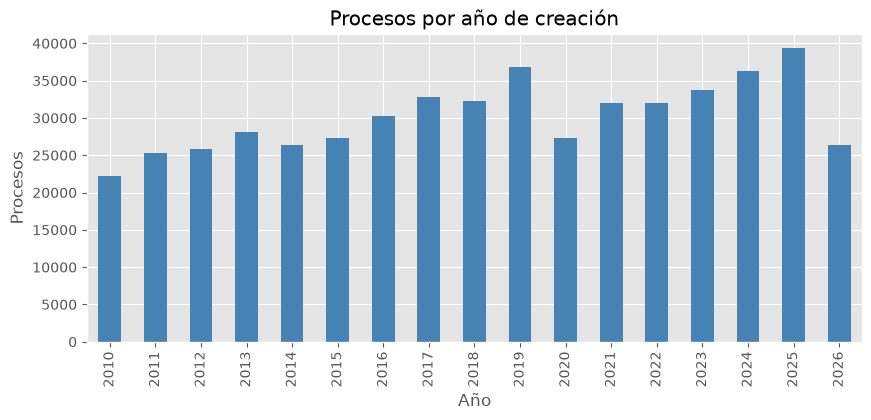

In [14]:
por_año = procesos.drop_duplicates('proceso_anonimizado')['a_o_creacion_proceso'].value_counts().sort_index()
por_año.plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.title('Procesos por año de creación')
plt.xlabel('Año')
plt.ylabel('Procesos')
plt.show()

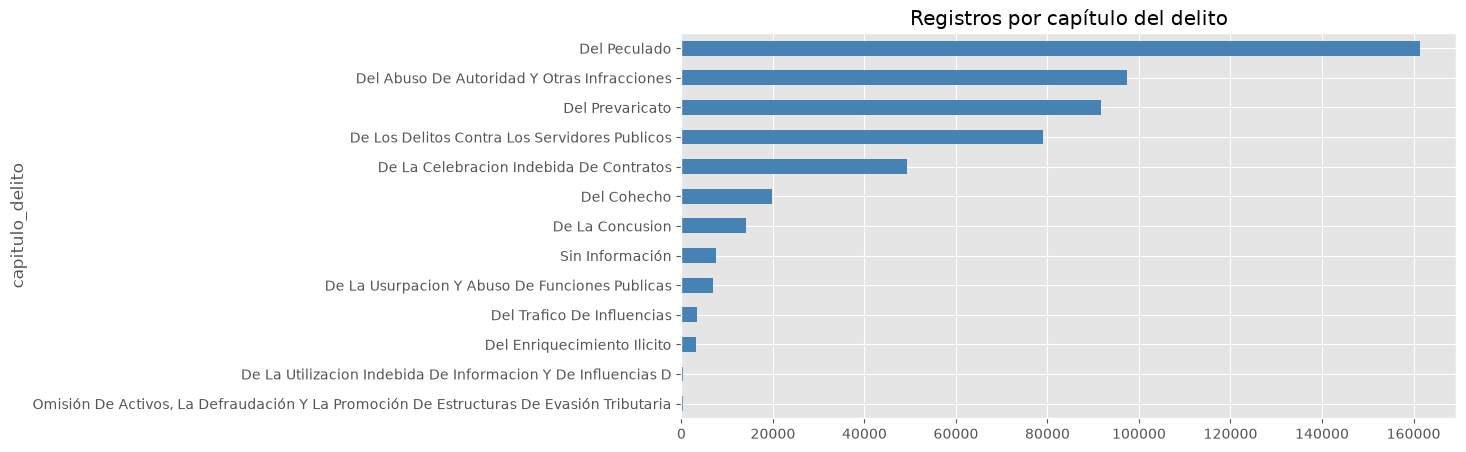

In [15]:
procesos['capitulo_delito'].value_counts().plot(kind='barh', figsize=(10, 5), color='steelblue')
plt.title('Registros por capítulo del delito')
plt.gca().invert_yaxis()
plt.show()

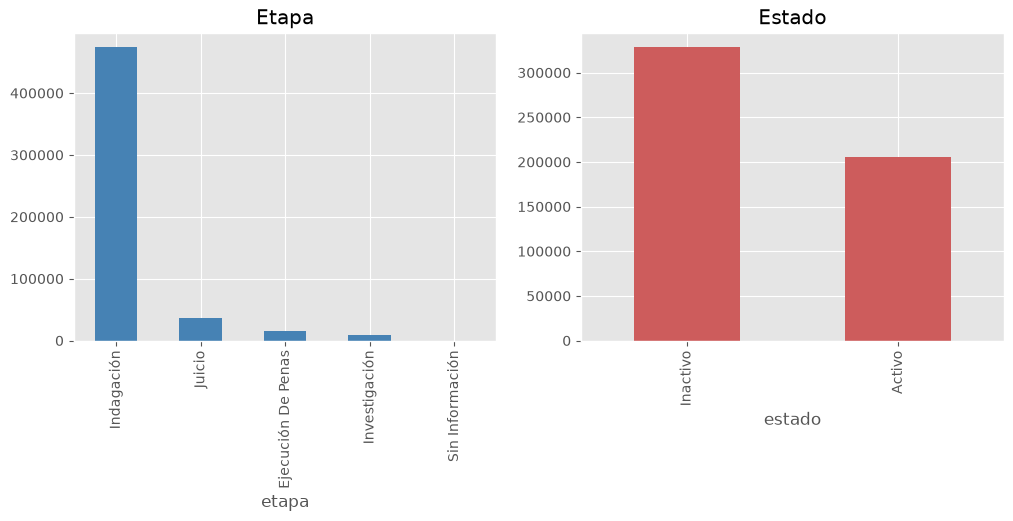

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
procesos['etapa'].value_counts().plot(kind='bar', ax=ax[0], color='steelblue', title='Etapa')
procesos['estado'].value_counts().plot(kind='bar', ax=ax[1], color='indianred', title='Estado')
plt.show()

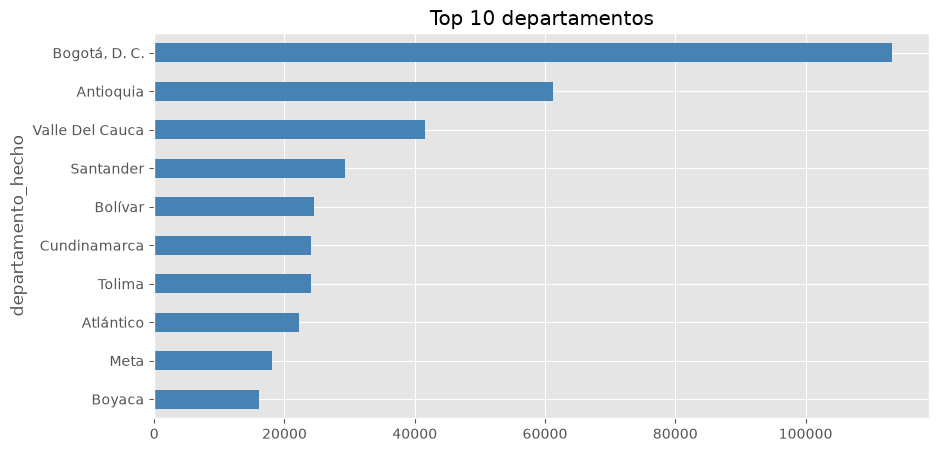

In [17]:
procesos['departamento_hecho'].value_counts().head(10).plot(kind='barh', figsize=(10, 5), color='steelblue')
plt.title('Top 10 departamentos')
plt.gca().invert_yaxis()
plt.show()

In [18]:
# Procesados (piva-db2c)
procesados = pd.read_csv("../data/bronze/fiscalia_procesados_raw.csv", dtype=str)
print(procesados.shape)
procesados.head()

(524480, 41)


,id_procesado_anonimizado,proceso_anonimizado,vinculacion_interviniente,deli_id,delito,titulo_delito,capitulo_delito,grado_delito,proceso_conexado,proceso_con_conexidad,...,etnia,comunidad_indigena,religioso,periodista,profesor,ddhh,discapacidad,categoria_procesado,tipo_sentencia,fecha_actualizacion_datos
0,2CB5E7326DBA3EC771E136BEDE28A89F4991D2E7F92ED8...,2CDC67C6F5A56F6BD617ADC6002CA5318ABAB255827CB6...,OTRA_VINCULACION,148,Delitos Contra La Administracion De Publica,Delitos Contra La Administracion De Publica,Sin Información,Ninguno,No,Si,...,Sin Información,Sin Información,No,No,No,No,Sin Información,Indiciado,No Aplica,30/09/2026
1,51668C882B5FAFDD721FAE45400E555189B67EBE31C891...,2CDC67C6F5A56F6BD617ADC6002CA5318ABAB255827CB6...,OTRA_VINCULACION,494,Enriquecimiento Ilicito Art. 412 C.P.,Delitos Contra La Administracion De Publica,Del Enriquecimiento Ilicito,Ninguno,No,Si,...,Sin Información,Sin Información,No,No,No,No,Sin Información,Indiciado,No Aplica,30/09/2026
2,51668C882B5FAFDD721FAE45400E555189B67EBE31C891...,5425401AD33B56322A86E41FA9B2F7F9B5A0AB5C60826D...,OTRA_VINCULACION,474,Peculado Por Apropiacion Art. 397 C.P.,Delitos Contra La Administracion De Publica,Del Peculado,Ninguno,No,No,...,Sin Información,Sin Información,No,No,No,No,Sin Información,Indiciado,No Aplica,30/09/2026
3,51668C882B5FAFDD721FAE45400E555189B67EBE31C891...,5425401AD33B56322A86E41FA9B2F7F9B5A0AB5C60826D...,OTRA_VINCULACION,494,Enriquecimiento Ilicito Art. 412 C.P.,Delitos Contra La Administracion De Publica,Del Enriquecimiento Ilicito,Ninguno,No,No,...,Sin Información,Sin Información,No,No,No,No,Sin Información,Indiciado,No Aplica,30/09/2026
4,2CB5E7326DBA3EC771E136BEDE28A89F4991D2E7F92ED8...,2CDC67C6F5A56F6BD617ADC6002CA5318ABAB255827CB6...,OTRA_VINCULACION,492,Contrato Sin Cumplimiento De Requisitos Legale...,Delitos Contra La Administracion De Publica,De La Celebracion Indebida De Contratos,Ninguno,No,Si,...,Sin Información,Sin Información,No,No,No,No,Sin Información,Indiciado,No Aplica,30/09/2026


In [19]:
sin_info = (procesados == "Sin Información").sum()
pd.DataFrame({'sin_info': sin_info, 'porcentaje': (sin_info / len(procesados) * 100).round(2)}).query('sin_info > 0').sort_values('porcentaje', ascending=False)

,sin_info,porcentaje
comunidad_indigena,524466,100.00
discapacidad,524395,99.98
etnia,523746,99.86
identidad_genero_orient_sexual,523425,99.80
nivel_educativo,473767,90.33
grupo_etario,379908,72.44
pais_nacimiento,129394,24.67
sexo,121940,23.25
grado_delito,119864,22.85
capitulo_delito,6507,1.24


In [20]:
# Columnas casi vacias
for col in ['religioso', 'periodista', 'profesor', 'ddhh', 'aplica_lgbti', 'pais_nacimiento', 'grado_delito']:
    print(procesados[col].value_counts().head(), "\n")

religioso
No    524478
Si         2
Name: count, dtype: int64 

periodista
No    524399
Si        81
Name: count, dtype: int64 

profesor
No    524147
Si       333
Name: count, dtype: int64 

ddhh
No    524404
Si        76
Name: count, dtype: int64 

aplica_lgbti
No    523425
Si      1055
Name: count, dtype: int64 

pais_nacimiento
Colombia           393539
Sin Información    129394
Venezuela            1263
Ecuador                92
Estados Unidos         30
Name: count, dtype: int64 

grado_delito
Ninguno               398149
Sin Información       119864
Agravado                5623
Tentativa                587
Tentativa/Agravado       257
Name: count, dtype: int64 



In [21]:
# Meses como '7' y '07'
print(procesados['mes_hecho_origen'].unique())

<StringArray>
[             '07',              '01',              '04',              '09',
              '03',              '02',              '11',              '06',
              '05',              '08',              '12',              '10',
               '7',               '3',               '8',               '6',
               '5',               '1',               '2',               '4',
               '9', 'Sin Información']
Length: 22, dtype: str


In [22]:
# Duplicados
print("Filas duplicadas:", procesados.duplicated().sum())
print("Procesados repetidos:", procesados['id_procesado_anonimizado'].duplicated().sum())
print("Repetidos por procesado + proceso + delito:", procesados.duplicated(['id_procesado_anonimizado', 'proceso_anonimizado', 'deli_id']).sum())

Filas duplicadas: 70
Procesados repetidos: 37990


Repetidos por procesado + proceso + delito: 11723


In [23]:
# Sentencias
print(procesados['categoria_procesado'].value_counts(), "\n")
print(procesados['tipo_sentencia'].value_counts())

categoria_procesado
Indiciado      443733
Acusado         43905
Sentenciado     28867
Imputado         7975
Name: count, dtype: int64 

tipo_sentencia
No Aplica     495613
Condenado      20783
Absuelto        6088
Sancionado      1996
Name: count, dtype: int64


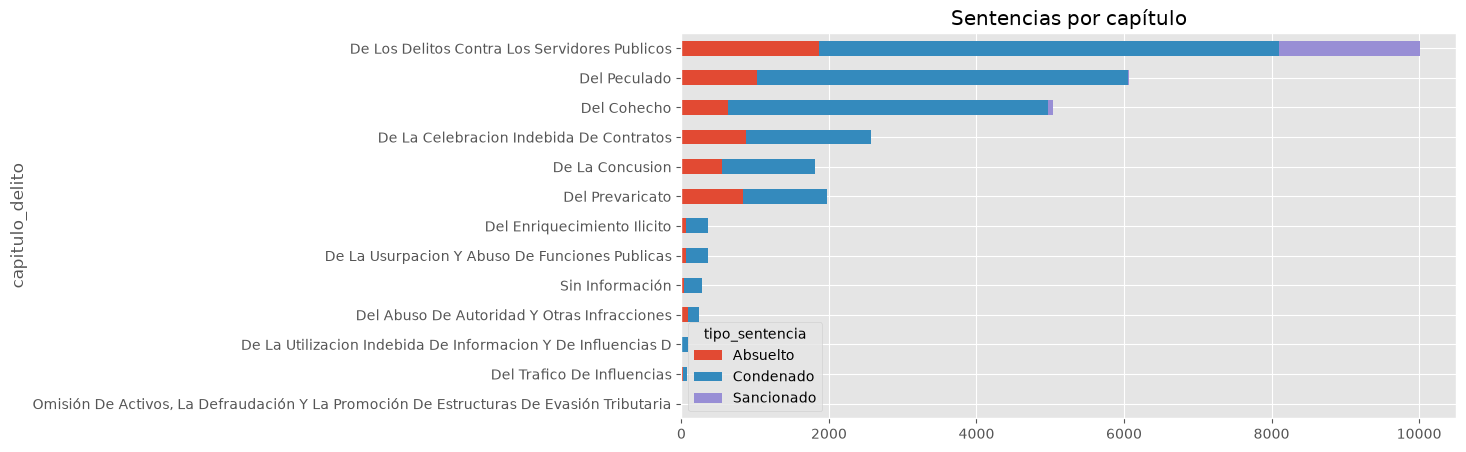

In [24]:
condenas = pd.crosstab(procesados['capitulo_delito'], procesados['tipo_sentencia'])
condenas = condenas.drop(columns='No Aplica').sort_values('Condenado')
condenas.plot(kind='barh', stacked=True, figsize=(10, 5))
plt.title('Sentencias por capítulo')
plt.show()

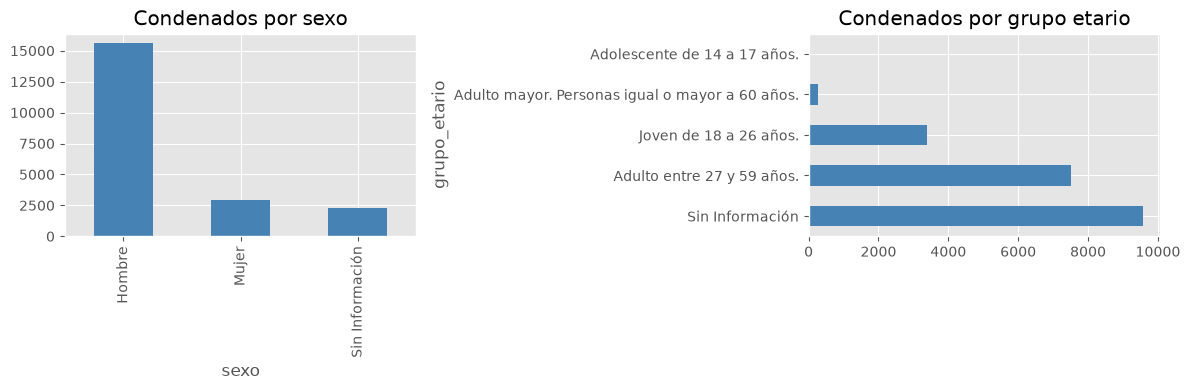

In [25]:
condenados = procesados[procesados['tipo_sentencia'] == 'Condenado']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
condenados['sexo'].value_counts().plot(kind='bar', ax=ax[0], color='steelblue', title='Condenados por sexo')
condenados['grupo_etario'].value_counts().plot(kind='barh', ax=ax[1], color='steelblue', title='Condenados por grupo etario')
plt.tight_layout()
plt.show()